In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

results_pc1 = f"results/PC1"
results_pc2 = "results/PC2"

# Ítem A

In [2]:
df_a = pd.read_csv(f"{results_pc1}/item_a.csv")
df_a["Computador"] = "PC1"
df_a

,N,n,tiempo_ms,checksum,Computador
0,2048,2048,2478.54,172.331627,PC1
1,2048,1024,1480.75,172.331627,PC1
2,2048,512,1309.73,172.331627,PC1
3,2048,256,1567.96,172.331627,PC1
4,2048,128,1774.31,172.331627,PC1
5,2048,64,2120.78,172.331627,PC1
6,2048,32,2048.86,172.331627,PC1


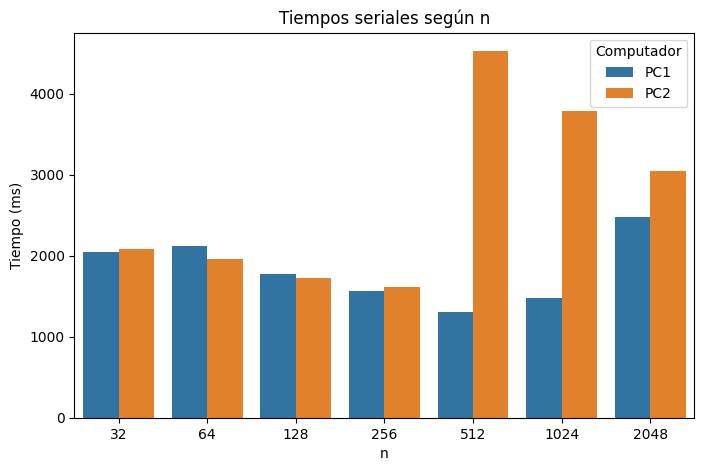

In [3]:
df_a2 = pd.read_csv(f"{results_pc2}/item_a.csv")
df_a2["Computador"] = "PC2"

df_a = pd.concat([df_a, df_a2])

fig, ax = plt.subplots(figsize=(8,5))

sns.barplot(data=df_a, x="n", y="tiempo_ms", hue="Computador", ax=ax)

ax.set_title(f"Tiempos seriales según n")
ax.set_ylabel("Tiempo (ms)")
plt.show()

In [4]:
def peso_hoja(n: int):
    # Multiplicar A, B y C
    peso_bytes = n*n * 3 * 8
    print(f"{peso_bytes} bytes")
    print(f"{peso_bytes/1_048_576:.2f} MB")

for n in [2048, 1024, 512, 256, 128, 64, 32]:
    print(f"n={n}")
    peso_hoja(n)
    print("---------------")

n=2048
100663296 bytes
96.00 MB
---------------
n=1024
25165824 bytes
24.00 MB
---------------
n=512
6291456 bytes
6.00 MB
---------------
n=256
1572864 bytes
1.50 MB
---------------
n=128
393216 bytes
0.38 MB
---------------
n=64
98304 bytes
0.09 MB
---------------
n=32
24576 bytes
0.02 MB
---------------


# Algoritmo 1

In [5]:
def calcular(df):
    t1_map = df[df['p'] == 1].set_index('N')['tiempo_ms']
    df['T1'] = df['N'].map(t1_map)

    df['Speedup'] = (df['T1'] / df['tiempo_ms']).round(2)
    df['Eficiencia'] = (df['Speedup'] / df['p']).round(2)

    return df

In [6]:
df_1 = pd.read_csv(f"{results_pc1}/alg_1.csv")
df_1 = calcular(df_1)
df_1["Computador"] = "PC1"

df_11 = pd.read_csv(f"{results_pc2}/alg_1.csv")
df_11 = calcular(df_11)
df_11["Computador"] = "PC2"

df_1 = pd.concat([df_1, df_11])
df_1

,N,p,tiempo_ms,checksum,T1,Speedup,Eficiencia,Computador
0,1024,1,134.42,52.223927,134.42,1.00,1.00,PC1
1,1024,2,64.83,52.223927,134.42,2.07,1.03,PC1
2,1024,4,35.40,52.223927,134.42,3.80,0.95,PC1
3,1024,8,38.10,52.223927,134.42,3.53,0.44,PC1
4,2048,1,2381.95,172.331627,2381.95,1.00,1.00,PC1
5,2048,2,1493.18,172.331627,2381.95,1.60,0.80,PC1
6,2048,4,818.10,172.331627,2381.95,2.91,0.73,PC1
7,2048,8,428.95,172.331627,2381.95,5.55,0.69,PC1
8,4096,1,19625.36,125.903028,19625.36,1.00,1.00,PC1
9,4096,2,12572.25,125.903028,19625.36,1.56,0.78,PC1


In [7]:
def imprimir_tabla(df):
    a = df[df["N"] == 2048]

    i = 0
    for fila in a.itertuples():
        print(fila.p, "&", fila.tiempo_ms, "&", fila.Speedup, "&", fila.Eficiencia, end="")
        if i < 4:
            print(" & ")
        else:
            print(" \\\\")
        i += 1

imprimir_tabla(df_1)

1 & 2381.95 & 1.0 & 1.0 & 
2 & 1493.18 & 1.6 & 0.8 & 
4 & 818.1 & 2.91 & 0.73 & 
8 & 428.95 & 5.55 & 0.69 & 
1 & 3034.33 & 1.0 & 1.0 \\
2 & 1563.13 & 1.94 & 0.97 \\
4 & 1778.09 & 1.71 & 0.43 \\
8 & 1063.53 & 2.85 & 0.36 \\


# Algoritmo 2

In [8]:
def calcular_optimo(df, n):
    df_best = df[df['n'] == n].copy()

    # Mapear T(1) dinámicamente según el valor de N para n=256
    t1_map_2 = df_best[df_best['p'] == 1].set_index('N')['tiempo_ms']
    df_best['T1'] = df_best['N'].map(t1_map_2)

    df_best['Speedup'] = (df_best['T1'] / df_best['tiempo_ms']).round(2)
    df_best['Eficiencia'] = (df_best['Speedup'] / df_best['p']).round(2)

    return df_best

In [9]:
df_2 = pd.read_csv(f"{results_pc1}/alg_2.csv")
df_2["Computador"] = "PC1"
df_2_best = calcular_optimo(df_2, 512)

df_22 = pd.read_csv(f"{results_pc2}/alg_2.csv")
df_22["Computador"] = "PC2"
df_22_best = calcular_optimo(df_22, 128)

df_best = pd.concat([df_2_best, df_22_best])
df_best

,N,n,p,tiempo_ms,checksum,Computador,T1,Speedup,Eficiencia
8,1024,512,1,159.27,52.223927,PC1,159.27,1.00,1.00
9,1024,512,2,82.79,52.223927,PC1,159.27,1.92,0.96
10,1024,512,4,45.33,52.223927,PC1,159.27,3.51,0.88
11,1024,512,8,47.17,52.223927,PC1,159.27,3.38,0.42
36,2048,512,1,1280.14,172.331627,PC1,1280.14,1.00,1.00
37,2048,512,2,645.17,172.331627,PC1,1280.14,1.98,0.99
38,2048,512,4,334.65,172.331627,PC1,1280.14,3.83,0.96
39,2048,512,8,297.03,172.331627,PC1,1280.14,4.31,0.54
64,4096,512,1,10337.89,125.903028,PC1,10337.89,1.00,1.00
65,4096,512,2,5430.21,125.903028,PC1,10337.89,1.90,0.95


In [10]:
imprimir_tabla(df_best)

1 & 1280.14 & 1.0 & 1.0 & 
2 & 645.17 & 1.98 & 0.99 & 
4 & 334.65 & 3.83 & 0.96 & 
8 & 297.03 & 4.31 & 0.54 & 
1 & 1895.42 & 1.0 & 1.0 \\
2 & 926.24 & 2.05 & 1.02 \\
4 & 632.1 & 3.0 & 0.75 \\
8 & 647.32 & 2.93 & 0.37 \\


# Algoritmo 3

In [11]:
df_3 = pd.read_csv(f"{results_pc1}/alg_3.csv")
df_3 = calcular(df_3)
df_3["Computador"] = "PC1"

df_33 = pd.read_csv(f"{results_pc2}/alg_3.csv")
df_33 = calcular(df_33)
df_33["Computador"] = "PC2"

df_3 = pd.concat([df_3, df_33])
df_3

,N,p,tiempo_ms,checksum,T1,Speedup,Eficiencia,Computador
0,1024,1,98.12,52.223927,98.12,1.00,1.00,PC1
1,1024,2,53.18,52.223927,98.12,1.85,0.92,PC1
2,1024,4,36.56,52.223927,98.12,2.68,0.67,PC1
3,1024,8,29.28,52.223927,98.12,3.35,0.42,PC1
4,2048,1,2165.25,172.331627,2165.25,1.00,1.00,PC1
5,2048,2,1424.44,172.331627,2165.25,1.52,0.76,PC1
6,2048,4,740.52,172.331627,2165.25,2.92,0.73,PC1
7,2048,8,403.21,172.331627,2165.25,5.37,0.67,PC1
8,4096,1,18875.74,125.903028,18875.74,1.00,1.00,PC1
9,4096,2,12125.29,125.903028,18875.74,1.56,0.78,PC1


In [12]:
imprimir_tabla(df_3)

1 & 2165.25 & 1.0 & 1.0 & 
2 & 1424.44 & 1.52 & 0.76 & 
4 & 740.52 & 2.92 & 0.73 & 
8 & 403.21 & 5.37 & 0.67 & 
1 & 2908.06 & 1.0 & 1.0 \\
2 & 1584.41 & 1.84 & 0.92 \\
4 & 1492.07 & 1.95 & 0.49 \\
8 & 960.0 & 3.03 & 0.38 \\


# Ítem E

In [13]:
def graficar(data, titulo: str):
    df = data[(data["N"] == 2048)]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.lineplot(data=df, x="p", y="tiempo_ms", hue="Computador", marker="o", ax=axes[0])
    axes[0].set_title("Tiempo T(p)")
    axes[0].set_ylabel("Tiempo (ms)")
    axes[0].set_xlabel("Cores lógicos")
    axes[0].grid(True)
    axes[0].legend()

    sns.lineplot(data=df, x="p", y="Speedup", hue="Computador", marker="o", ax=axes[1])
    axes[1].axline((1, 1), slope=1, color='red', linestyle=':', label='Ideal')
    axes[1].set_ylim(1,8)
    axes[1].set_title("Speedup S(p)")
    axes[1].set_ylabel("Speedup")
    axes[1].set_xlabel("Cores lógicos")
    axes[1].grid(True)
    axes[1].legend()

    sns.lineplot(data=df, x="p", y="Eficiencia", hue="Computador", marker="o", ax=axes[2])
    axes[2].axline((1, 1), slope=0, color='red', linestyle=':', label='Ideal')
    axes[2].set_ylim(0,1.1)
    axes[2].set_title("Eficiencia E(p)")
    axes[2].set_ylabel("Eficiencia")
    axes[2].set_xlabel("Cores lógicos")
    axes[2].grid(True)
    axes[2].legend()

    fig.suptitle(titulo)
    plt.show()

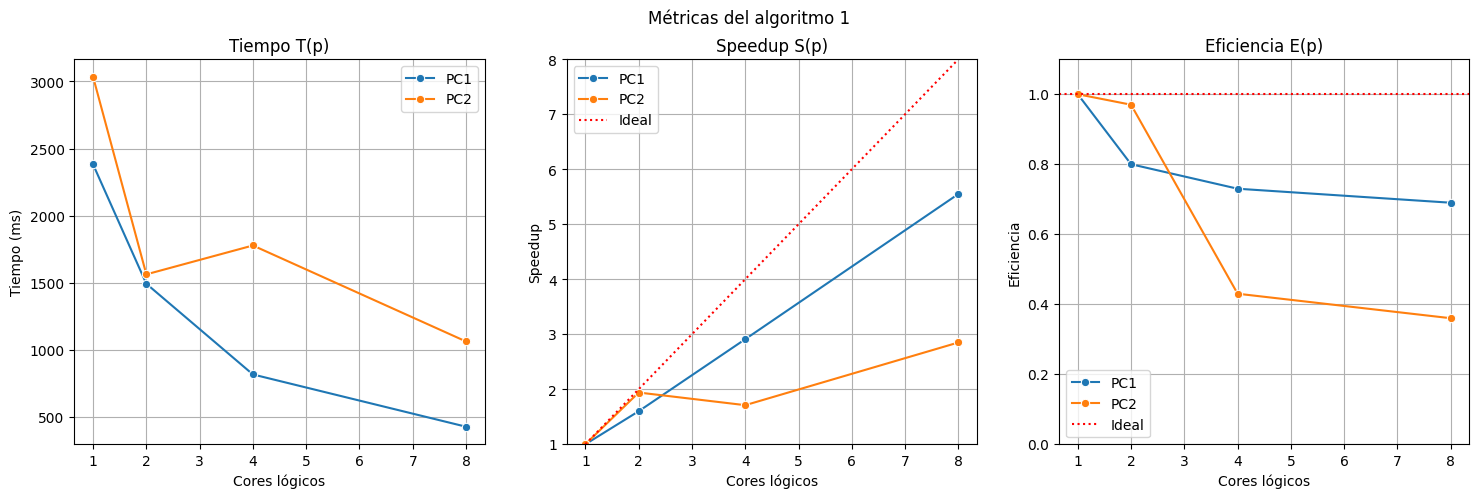

In [14]:
graficar(df_1, "Métricas del algoritmo 1")

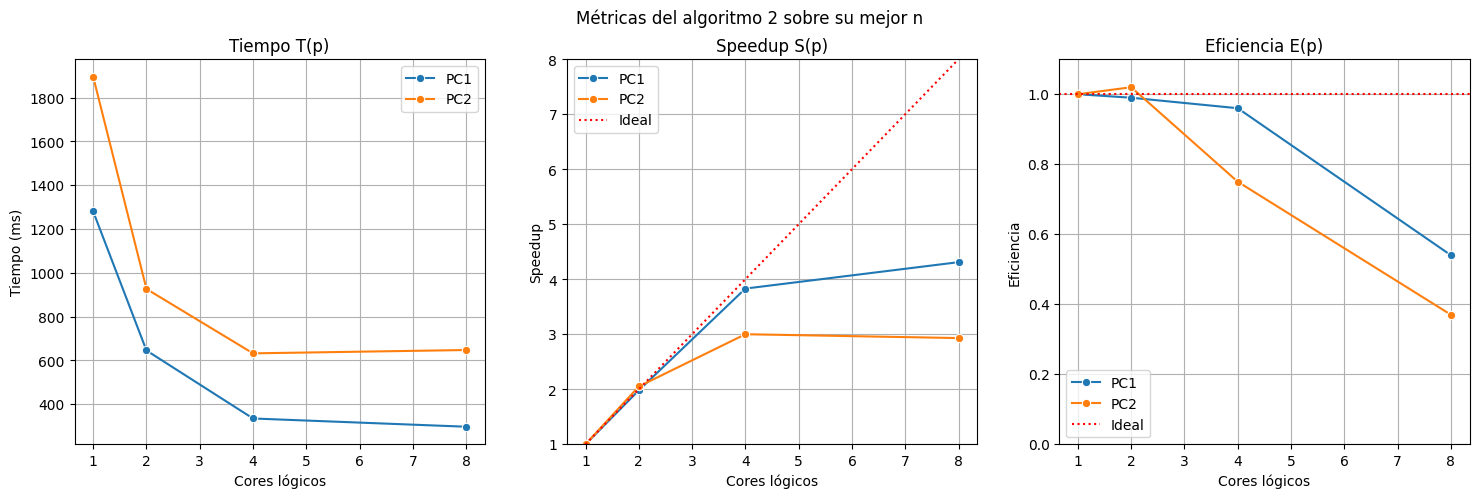

In [15]:
graficar(df_best, "Métricas del algoritmo 2 sobre su mejor n")

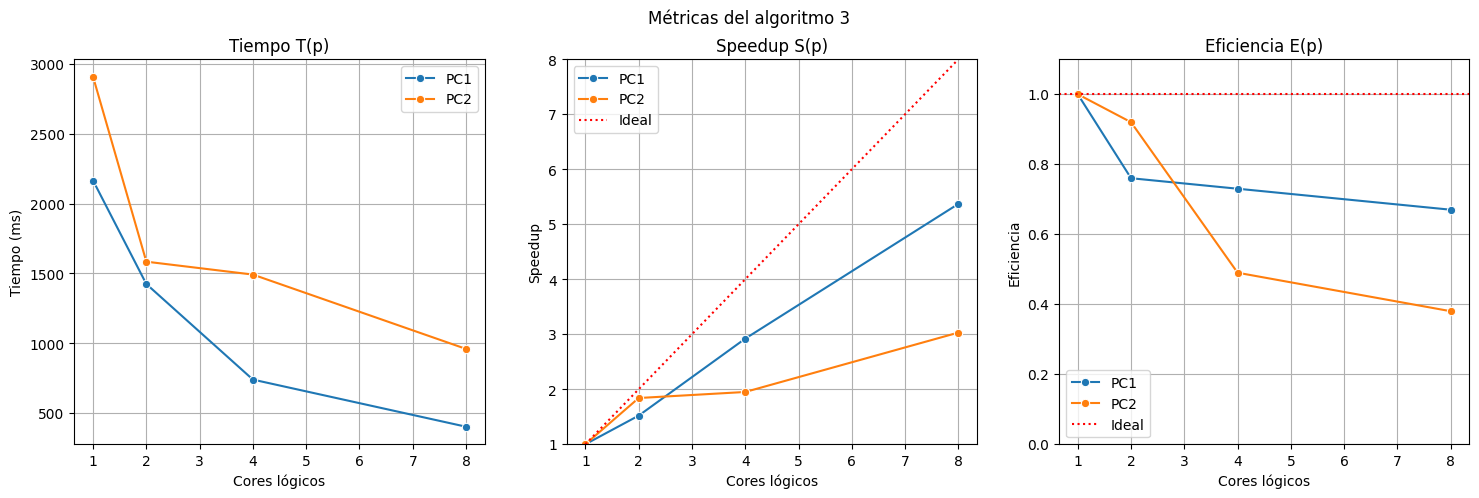

In [16]:
graficar(df_3, "Métricas del algoritmo 3")

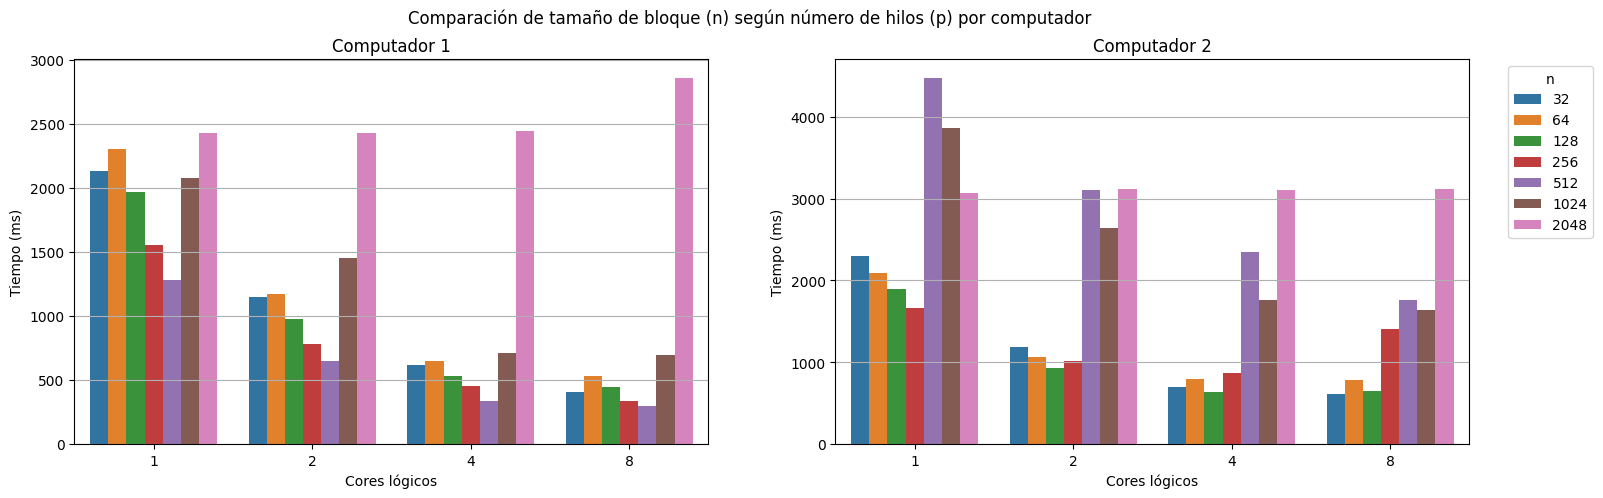

In [17]:
data_pc1 = df_2[(df_2["N"] == 2048)]
data_pc1["n"] = data_pc1["n"].astype("category")
data_pc2 = df_22[(df_22["N"] == 2048)]
data_pc2["n"] = data_pc2["n"].astype("category")

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.barplot(data=data_pc1, x="p", y="tiempo_ms", hue="n", ax=axes[0])
axes[0].set_title("Computador 1")
axes[0].set_ylabel("Tiempo (ms)")
axes[0].set_xlabel("Cores lógicos")
axes[0].grid(True, axis="y")
axes[0].legend().set_visible(False)

sns.barplot(data=data_pc2, x="p", y="tiempo_ms", hue="n", ax=axes[1])
axes[1].set_title("Computador 2")
axes[1].set_ylabel("Tiempo (ms)")
axes[1].set_xlabel("Cores lógicos")
axes[1].grid(True, axis="y")
axes[1].legend(title="n", bbox_to_anchor=(1.05, 1), loc='upper left')


fig.suptitle("Comparación de tamaño de bloque (n) según número de hilos (p) por computador")
plt.show()